# POD for 0D Isothermal Chemical Reactor
### Importing libraries

In [1]:
import os
import sys
import time
import pyDOE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PCAfold import PCA

sys.path.append(os.path.normpath(os.environ['WORKSPACE_PATH'] + '/ML/PrODE/prode.22.01/'))
from physics.data_generator import DataGenerator

### Generating Training and Test Data Set
Input parameters

In [23]:
# Training/Testing data
train_cases = 5
test_cases = 1

# Physical model
# =============================================================================
# Input space (limit values)
input_space = {
    'Ttr':  [8.e3,   1.5e4],        # Tanslational temperature [K]
    'T0':   [1.e3,   8.e3],         # Initial temperature [K]
    'P0':   [1.e3,   1.e4],         # Initial pressure [Pa]
    'XO2':  [0.05e0, 1.e0]          # Initial O2 mole fraction
}

# Time (limit values)
time_limit = [1.e-14, 1.e-1]

# Timescales thermochemistry --------------------------------------------------
groups = ['RVE1', 'RVE3', 'RVE9', 'RVE18']

groups_graph = {
    0: {
        0: {
            0: [0,1],
            1: [2,3],
            2: [4,5],
        },
        1: {
            3: [6,7],
            4: [8,9],
            5: [10,11],
        },
        2: {
            6: [12,13],
            7: [14,15],
            8: [16,17],
        },
    }
}

# Thermochemistry -------------------------------------------------------------
species = {
    'O2': {
        'rovib': {
            'system': 'O3',
            'PES': 'UMN',
            'grouping': 'RVE18'
        }
    },
    'O': None
}

process_flags = {      # Reactive processes
    'excit': 1,
    'diss':  1
}

Solve ODEs

In [3]:
dataGen = DataGenerator(
    train_cases,
    test_cases,
    time_limit,
    input_space,
    species,
    process_flags,
    groups_graph
)

ic = dataGen.initial_cond()
train_cases = dataGen.generate(ic[0], name='train')
test_cases = dataGen.generate(ic[1], name='test')

  0%|          | 0/10 [00:00<?, ?it/s]

Generating initial conditions ...
Generating train data ...


100%|██████████| 1/1 [00:00<00:00, 1804.00it/s]

Generating test data ...


### Eigenmodes Analysis
Input parameters

In [31]:
pod_dir = './pod'
pod_type = 'all'

if not os.path.exists(pod_dir+'/'+str(pod_type)):
    os.makedirs(pod_dir+'/'+str(pod_type))

nPODs = 8

acceptance_tol = 1.e-3

eig_min = 1.e-10
scalings = ['none', 'auto', 'std', 'pareto', 'vast', 'range']

[['Y_O2', 'Y_O'], ['Y_11', 'Y_12', 'Y_13'], ['Y_21', 'Y_22', 'Y_23', 'Y_24', 'Y_25', 'Y_26', 'Y_27', 'Y_28', 'Y_29'], ['Y_31', 'Y_32', 'Y_33', 'Y_34', 'Y_35', 'Y_36', 'Y_37', 'Y_38', 'Y_39', 'Y_310', 'Y_311', 'Y_312', 'Y_313', 'Y_314', 'Y_315', 'Y_316', 'Y_317', 'Y_318']]


In [13]:
def delta_fn(y, z):
    return np.mean(np.abs((y - z) / y), axis=0)

if pod_type == 'all':
    first = True
    for case in train_cases:
        y = case[1]
        if first:
            Y = y
            first = False
        else:
            for i in range(len(Y)):
                for j in range(y[i].shape[1]):
                    delta = delta_fn(y[i][:,j:j+1], Y[i])
                    if any(delta < acceptance_tol):
                        continue
                    else:
                        Y[i] = np.hstack((Y[i], y[i][:,j:j+1]))
else:
    raise ValueError()

>> POD for RVE1 coarse-grained model dynamics


<Figure size 432x288 with 0 Axes>

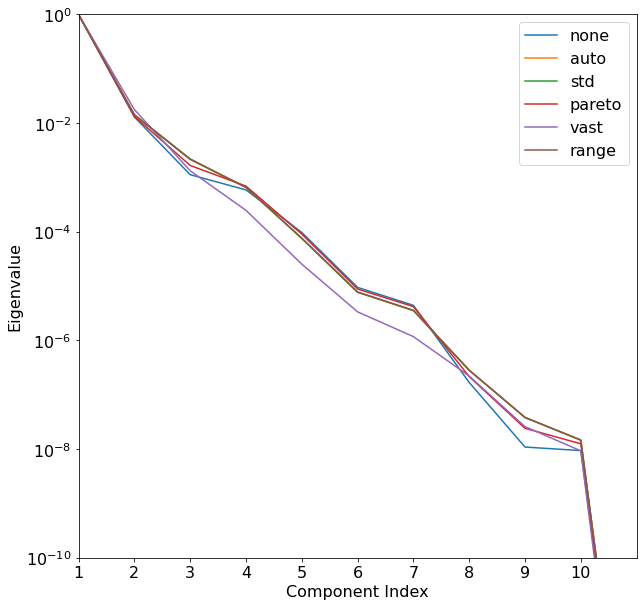

>> POD for RVE3 coarse-grained model dynamics


<Figure size 432x288 with 0 Axes>

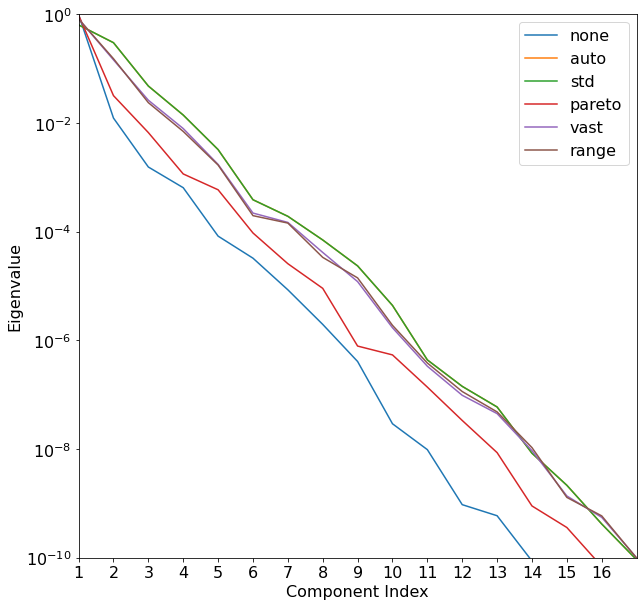

>> POD for RVE9 coarse-grained model dynamics


<Figure size 432x288 with 0 Axes>

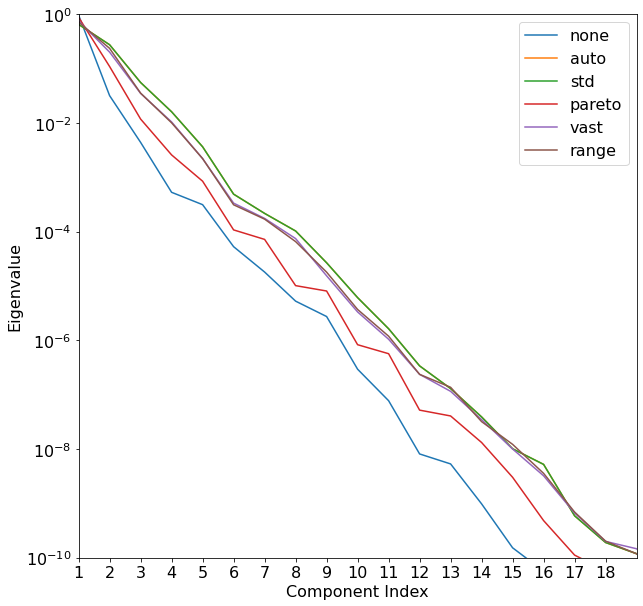

>> POD for RVE18 coarse-grained model dynamics


<Figure size 432x288 with 0 Axes>

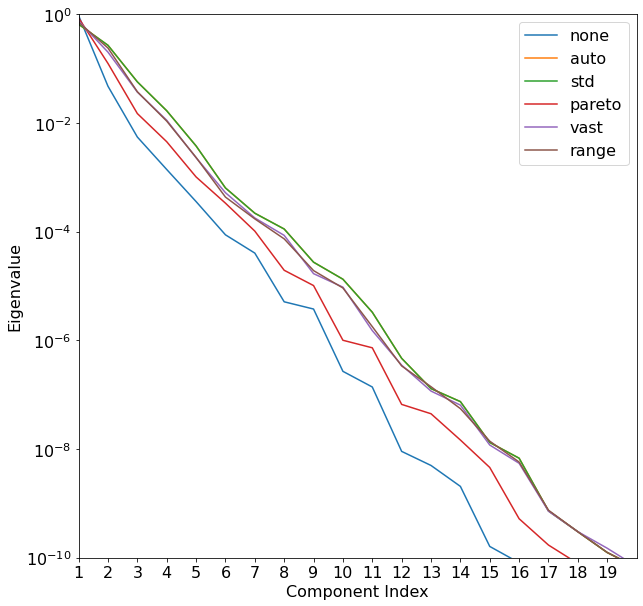

{'RVE1': 10, 'RVE3': 16, 'RVE9': 18, 'RVE18': 19}


In [58]:
nPC = {}
for i, y in enumerate(Y):
    print(f'>> POD for {groups[i]} coarse-grained model dynamics')
    for j, sc in enumerate(scalings):
        pca = PCA(
            y,
            scaling=sc,
            n_components=nPODs,
            use_eigendec=True,
            nocenter=False
        )
        if j == 0:
            L = pca.L.reshape(-1,1)
        else:
            L = np.hstack((L, pca.L.reshape(-1,1)))
    nPC_cg = max(np.argmin(np.abs(L - eig_min), axis=0))
    nPC[groups[i]] = nPC_cg

    fig = plt.figure()
    plt.figure(figsize=(10,10))
    # Y axis
    plt.ylim([eig_min, None])
    plt.ylabel('Eigenvalue')
    plt.yscale('log')
    # X axis
    plt.xlabel('Component Index')
    plt.xticks(np.arange(0,nPC_cg), labels=np.arange(1,nPC_cg+1))
    plt.xlim([0,nPC_cg])
    # Plot
    plt.plot(L, label=scalings)
    plt.legend()
    plt.show()
    plt.close()


In [ ]:
for i, y in enumerate(Y):
    print(f'>> Reconstruction PCA error for {groups[i]} coarse-grained model dynamics')
    for nPC_k in range(1, nPC.values()+1):
        for j, sc in enumerate(scalings):
            pca = PCA(
                y,
                scaling=sc,
                n_components=nPC_k,
                use_eigendec=True,
                nocenter=False
            )
            # Calculate the principal components
            pc = pca.transform(y)
            # Calculate the reconstructed variables
            y_rec = pca.reconstruct(pc)
            if j == 0:
                L = pca.L.reshape(-1,1)
            else:
                L = np.hstack((L, pca.L.reshape(-1,1)))
        nPC_cg = max(np.argmin(np.abs(L - eig_min), axis=0))
        nPC[groups[i]] = nPC_cg

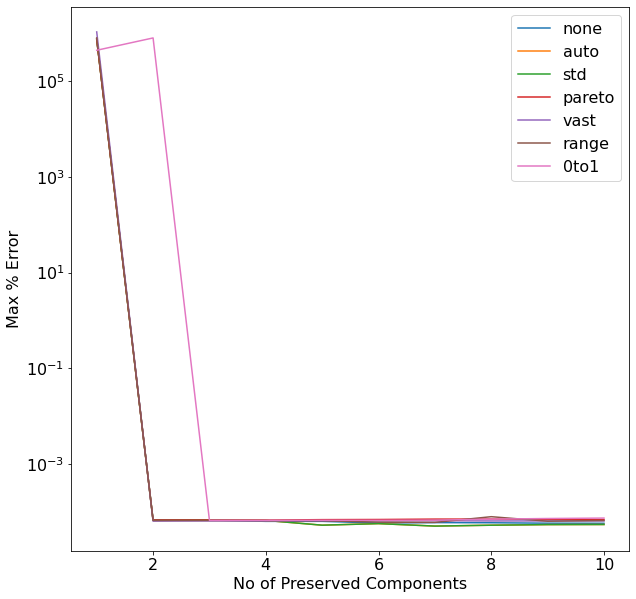

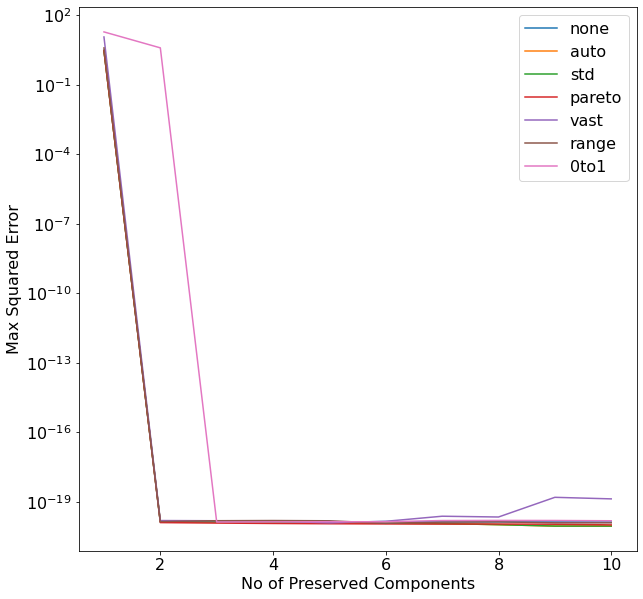

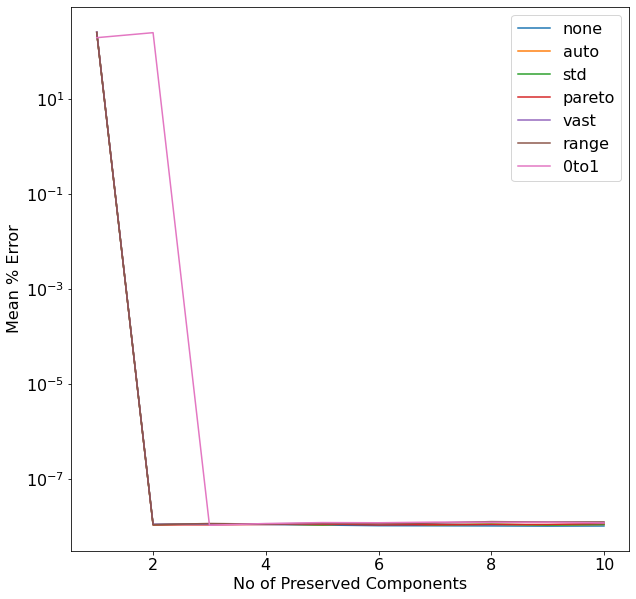

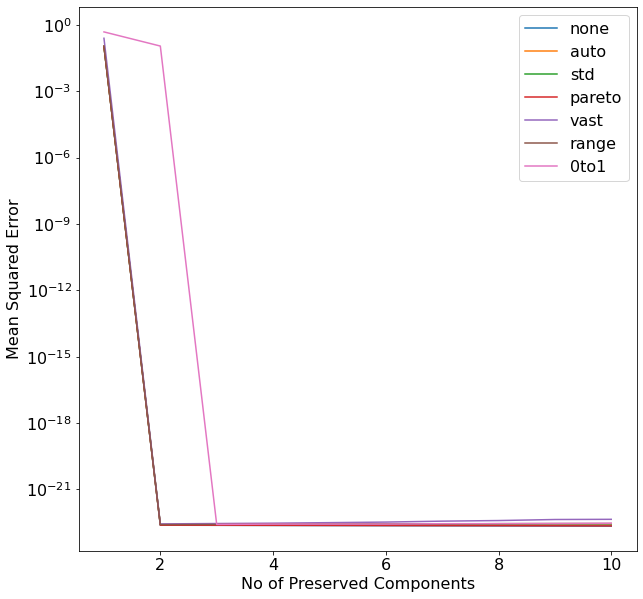

In [9]:
NPODsVec   = np.arange(1,11,1)
ScalingVec = ['none', 'auto', 'std', 'pareto', 'vast', 'range', '0to1']
#'none', '', 'auto', 'std', 'pareto', 'vast', 'range', '0to1', '-1to1', 'level', 'max', 'poisson', 'vast_2', 'vast_3', 'vast_4'

MaxPerc    = np.zeros((len(NPODsVec), len(ScalingVec)))
MaxSE      = np.zeros((len(NPODsVec), len(ScalingVec)))
MeanPerc   = np.zeros((len(NPODsVec), len(ScalingVec)))
MSE        = np.zeros((len(NPODsVec), len(ScalingVec)))
for i, NPODs in enumerate(NPODsVec):
    #print('NPODs = ', NPODs)
    
    for j, Scaling in enumerate(ScalingVec):

        pca        = PCAA(yMat, scaling=Scaling, n_components=int(NPODs))
        C          = pca.X_center
        D          = pca.X_scale
        A          = pca.A[:,0:NPODs].T
        L          = pca.L
        AT         = A.T

        yMat_pca   = ((yMat - C)/D).dot(AT)
        yMat_      = (yMat_pca.dot(A))*D + C
        
        
        MaxPerc[i,j]    = np.max(abs((yMat - yMat_)/yMat)*100)
        MaxSE[i,j]      = np.max((yMat - yMat_)**2)
        MeanPerc[i,j]   = np.mean(abs((yMat - yMat_)/yMat)*100)
        MSE[i,j]        = np.mean((yMat - yMat_)**2)

plt.figure(figsize=(10,10))
plt.plot(NPODsVec, MaxPerc, label=ScalingVec)
plt.xlabel('No of Preserved Components')
plt.ylabel('Max % Error')
plt.legend()
plt.yscale('log')

plt.figure(figsize=(10,10))
plt.plot(NPODsVec, MaxSE, label=ScalingVec)
plt.xlabel('No of Preserved Components')
plt.ylabel('Max Squared Error')
plt.legend()
plt.yscale('log')

plt.figure(figsize=(10,10))
plt.plot(NPODsVec, MeanPerc, label=ScalingVec)
plt.xlabel('No of Preserved Components')
plt.ylabel('Mean % Error')
plt.legend()
plt.yscale('log')

plt.figure(figsize=(10,10))
plt.plot(NPODsVec, MSE, label=ScalingVec)
plt.xlabel('No of Preserved Components')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.yscale('log')

In [10]:
pca        = PCAA(yMat, scaling='none', n_components=NPODsFinal, nocenter=False)
C          = pca.X_center
D          = pca.X_scale
A          = pca.A[:,0:NPODsFinal].T
L          = pca.L
AT         = A.T
yMat_Scaled= ((yMat - C)/D)
print('[PCA] Shape of A        = ', A.shape)
print('[PCA] ')

[PCA] Shape of A        =  (2, 100)
[PCA] 


In [11]:
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/ROM/')
except:
    pass

FileName    = OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/ROM/A.csv'
np.savetxt(FileName, A, delimiter=',')

FileName    = OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/ROM/C.csv'
np.savetxt(FileName, C, delimiter=',')

FileName    = OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/ROM/D.csv'
np.savetxt(FileName, D, delimiter=',')

FileName    = OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/ROM/yMat_Scaled.csv'
np.savetxt(FileName, yMat_Scaled, delimiter=',')

In [12]:
#yMat_pca    = pca.transform(yMat, nocenter=False)
yMat_pca   = ((yMat - C)/D).dot(AT)

yMat_      = (yMat_pca.dot(A))*D + C
print('[PCA] Shape of yMat_pca = ', yMat_pca.shape)
print('[PCA]  Max % Error = ', np.max(abs((yMat - yMat_)/yMat)*100))
print('[PCA]  Max      SE = ', np.max((yMat - yMat_)**2))
print('[PCA] Mean % Error = ', np.mean(abs((yMat - yMat_)/yMat)*100))
print('[PCA]          MSE = ', np.mean((yMat - yMat_)**2))

[PCA] Shape of yMat_pca =  (500, 2)
[PCA]  Max % Error =  6.784284866261668e-05
[PCA]  Max      SE =  1.3153584538930478e-20
[PCA] Mean % Error =  1.0861400081662507e-08
[PCA]          MSE =  2.4062322237516686e-23


Text(0.5, 0, '$\\alpha_{x_2}$')

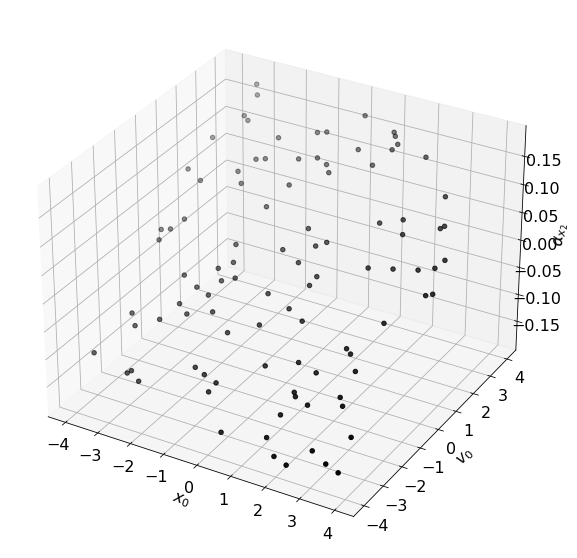

In [13]:
# %matplotlib qt

iVar    = 1

# fig = plt.figure()
# ax  = fig.add_subplot(projection='3d')
# ax.scatter(ICs[:,0], ICs[:,1], A[iVar,:], c='k')
# ax.set_xlabel(r'$\eta_{'+str(1)+'}$')
# ax.set_ylabel(r'$\eta_{'+str(2)+'}$')
# ax.set_zlabel(r'$\Psi_{'+str(iVar+1)+'}$')


fig = plt.figure(figsize=(10,10))
ax  = fig.add_subplot(projection='3d')
ax.scatter(ICs[:,0], ICs[:,1], A[iVar,:], c='k')
ax.set_xlabel(r'$x_{0}$')
ax.set_ylabel(r'$v_{0}$')
ax.set_zlabel(r'$\alpha_{x_'+str(iVar+1)+'}$')

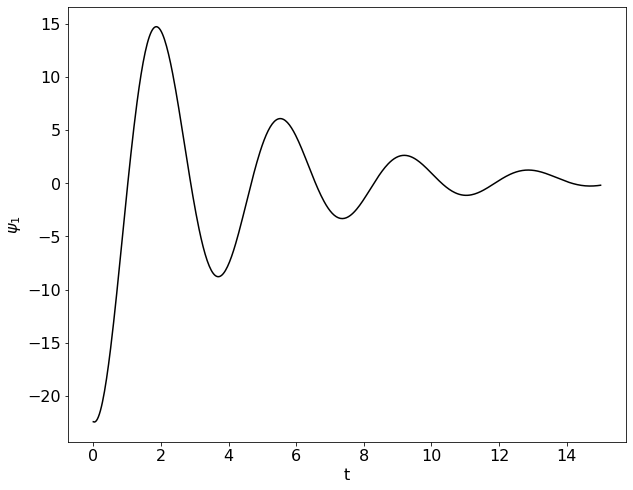

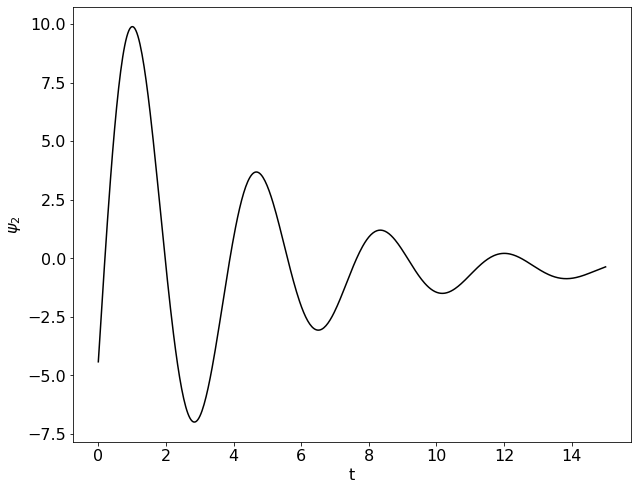

In [14]:
iVar = [0,1]

for i in iVar:
    plt.figure(figsize=(10,8))
    plt.plot(tVec, yMat_pca[:,i], '-k')
    plt.xlabel('t')
    plt.ylabel(r'$\psi_{'+str(i+1)+'}$')
    #plt.xscale('log')
    #plt.xlim([1.e-6,1.e-4])

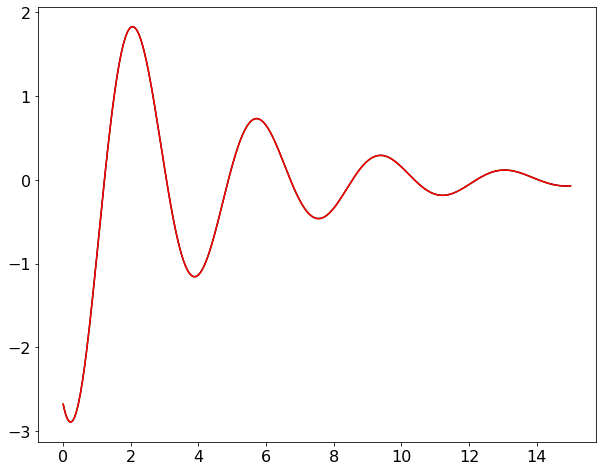

In [15]:
plt.figure(figsize=(10,8))
plt.plot(tVec, yMat[:,1], '-k')
plt.plot(tVec, yMat_[:,1], '-r')
#plt.xscale('log')

In [16]:
VarsPOD          = ['POD_'+str(iPOD+1) for iPOD in range(NPODsFinal)]
Data             = pd.DataFrame(yMat_pca, columns=VarsPOD)
#tVec[tVec == 0.] = FixedMinVal
Data['t']        = tVec
Data['log(t)']   = np.log(tVec)
Data['log10(t)'] = np.log10(tVec)


Data

/home/zanardi/.local/lib/python3.8/site-packages/pandas/core/arraylike.py:358: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/zanardi/.local/lib/python3.8/site-packages/pandas/core/arraylike.py:358: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


,POD_1,POD_2,t,log(t),log10(t)
0,-22.424408,-4.417123,0.00000,-inf,-inf
1,-22.453921,-3.725737,0.03006,-3.504556,-1.522009
2,-22.421719,-3.035854,0.06012,-2.811409,-1.220979
3,-22.328809,-2.349307,0.09018,-2.405944,-1.044888
4,-22.176347,-1.667893,0.12024,-2.118262,-0.919949
...,...,...,...,...,...
495,-0.228279,-0.427281,14.87976,2.700002,1.172596
496,-0.218412,-0.410872,14.90982,2.702020,1.173472
497,-0.207229,-0.394814,14.93988,2.704034,1.174347
498,-0.194782,-0.379144,14.96994,2.706044,1.175220


In [17]:
from sklearn.model_selection import train_test_split

try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME)
except:
    pass
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Trunk/')
except:
    pass
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Trunk/train/')
except:
    pass
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Trunk/valid/')
except:
    pass
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Trunk/test/')
except:
    pass

In [18]:
data_id    = 'pts'

DataNoZero           = Data#[Data['t'] >= FixedMinVal]
n_points             = len(DataNoZero)

idx                  = np.arange(n_points)
train_idx, valid_idx = train_test_split(idx, test_size=ValidPerc/100, random_state=42)

n_valid              = len(valid_idx)
n_train              = len(train_idx)


try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Trunk/train/'+data_id+'/')
except:
    pass
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Trunk/valid/'+data_id+'/')
except:
    pass

DataInput  = DataNoZero[['t', 'log10(t)', 'log(t)'] + VarsPOD]
DataInput.iloc[train_idx].to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Trunk/train/'+data_id+'/Input.csv', index=False)
DataInput.iloc[valid_idx].to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Trunk/valid/'+data_id+'/Input.csv', index=False)

DataOutput = DataNoZero[['t', 'log10(t)', 'log(t)'] + VarsPOD]
DataOutput.iloc[train_idx].to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Trunk/train/'+data_id+'/Output.csv', index=False)
DataOutput.iloc[valid_idx].to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Trunk/valid/'+data_id+'/Output.csv', index=False)

In [19]:
DataNoZero           = Data
n_points             = len(DataNoZero)

n_test               = n_points


try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Trunk/test/ext/')
except:
    pass

DataInput  = DataNoZero[['t', 'log10(t)', 'log(t)'] + VarsPOD]
DataInput.to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Trunk/test/ext/Input.csv', index=False)

DataOutput = DataNoZero[['t', 'log10(t)', 'log(t)'] + VarsPOD]
DataOutput.to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Trunk/test/ext/Output.csv', index=False)

In [20]:
from sklearn.model_selection import train_test_split

try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME)
except:
    pass

In [21]:
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch/')
except:
    pass
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch/train/')
except:
    pass
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch/valid/')
except:
    pass
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch/test/')
except:
    pass

In [22]:
data_id    = 'pts'

n_points             = len(DataIC)

idx                  = np.arange(n_points)
train_idx, valid_idx = train_test_split(idx, test_size=ValidPerc/100, random_state=42)

n_valid              = len(valid_idx)
n_train              = len(train_idx)

try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch/train/'+data_id+'/')
except:
    pass
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch/valid/'+data_id+'/')
except:
    pass

DataInput  = DataIC
DataInput.iloc[train_idx].to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch/train/'+data_id+'/Input.csv', index=False)
DataInput.iloc[valid_idx].to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch/valid/'+data_id+'/Input.csv', index=False)

DataOutput = pd.DataFrame(np.concatenate([A.T, C[...,np.newaxis], D[...,np.newaxis]], axis=1), columns=['POD_'+str(i+1) for i in range(A.shape[0])]+['C','D'])
DataOutput.iloc[train_idx].to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch/train/'+data_id+'/Output.csv', index=False)
DataOutput.iloc[valid_idx].to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch/valid/'+data_id+'/Output.csv', index=False)

In [23]:
n_points             = len(DataIC)

n_test               = n_points

try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch/test/ext/')
except:
    pass

DataInput  = DataIC
DataInput.to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch/test/ext/Input.csv', index=False)

DataOutput = pd.DataFrame(np.concatenate([A.T, C[...,np.newaxis], D[...,np.newaxis]], axis=1), columns=['POD_'+str(i+1) for i in range(A.shape[0])]+['C','D'])
DataOutput.to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch/test/ext/Output.csv', index=False)

In [24]:
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch_ICs/')
except:
    pass
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch_ICs/train/')
except:
    pass
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch_ICs/valid/')
except:
    pass
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch_ICs/test/')
except:
    pass

In [25]:
data_id    = 'pts'

n_points             = len(DataIC)


# idx                  = np.arange(n_points)
# train_idx, valid_idx = train_test_split(idx, test_size=ValidPerc/100, random_state=42)
idx                  = np.arange(n_points)
train_idx            = idx
valid_idx            = idx

n_valid              = len(valid_idx)
n_train              = len(train_idx)

try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch_ICs/train/'+data_id+'/')
except:
    pass
try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch_ICs/valid/'+data_id+'/')
except:
    pass

DataInput  = DataIC
DataInput.iloc[train_idx].to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch_ICs/train/'+data_id+'/Input.csv', index=False)
DataInput.iloc[valid_idx].to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch_ICs/valid/'+data_id+'/Input.csv', index=False)

YY = np.zeros((A.shape[1],A.shape[1]), dtype=int)
for i in range(YY.shape[0]):
    YY[i,i] = 1
DataYY = pd.DataFrame(YY, columns=['IC_'+str(i+1) for i in range(YY.shape[0])])
DataYY.iloc[train_idx].to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch_ICs/train/'+data_id+'/Output.csv', index=False)
DataYY.iloc[valid_idx].to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch_ICs/valid/'+data_id+'/Output.csv', index=False)

In [26]:
n_points             = len(DataIC)

n_test               = n_points

try:
    os.makedirs(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch_ICs/test/ext/')
except:
    pass

DataInput  = DataIC
DataInput.to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch_ICs/test/ext/Input.csv', index=False)

YY = np.zeros((A.shape[1],A.shape[1]), dtype=int)
for i in range(YY.shape[0]):
    YY[i,i] = 1
DataYY = pd.DataFrame(YY, columns=['IC_'+str(i+1) for i in range(YY.shape[0])])
DataYY.to_csv(OutputDir+'/'+str(PODType)+'/POD_'+POD_NAME+'/Branch_ICs/test/ext/Output.csv', index=False)

In [27]:
iPOD       = 1

DataInput  = DataIC
DataZZ     = pd.DataFrame(A.T, columns=['POD_'+str(i+1) for i in range(A.shape[0])])

n_points             = len(DataIC)
idx                  = np.arange(n_points)
train_idx, valid_idx = train_test_split(idx, test_size=ValidPerc/100, random_state=42)

X          = DataInput.iloc[train_idx].to_numpy()
Y          = DataZZ.iloc[train_idx].to_numpy()[:,iPOD-1]#[...,np.newaxis]

XX         = DataInput.iloc[valid_idx].to_numpy()
YY         = DataZZ.iloc[valid_idx].to_numpy()[:,iPOD-1]#[...,np.newaxis]

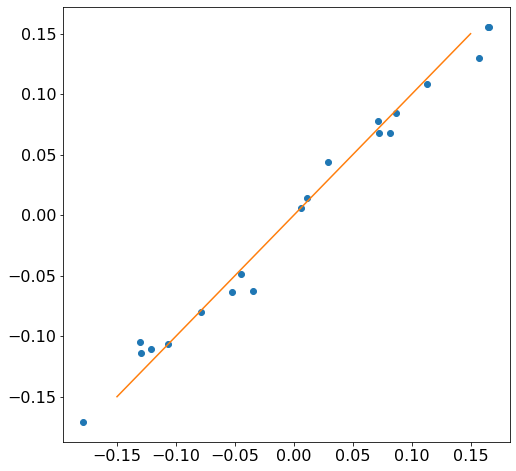

In [28]:
from sklearn.neighbors import KNeighborsRegressor
neigh = KNeighborsRegressor(n_neighbors=3, weights='distance', p=1)
neigh.fit(X, Y)

plt.figure(figsize=(8,8))
plt.plot(YY, neigh.predict(XX), 'o')
plt.plot([-0.15,0.15], [-0.15,0.15])